# **Proyecto Análisis de Portafolio **


In [ ]:
# Importamos os para crear carpetas donde guardar los resultados.
import os  # Permite trabajar con carpetas y archivos.

# Importamos pandas para organizar los datos en tablas.
import pandas as pd  # Es la biblioteca principal para trabajar con datos tabulares.

# Importamos NumPy para realizar cálculos matemáticos.
import numpy as np  # La usaremos para logaritmos y raíces cuadradas.

# Importamos yfinance para descargar precios históricos de Yahoo Finance.
import yfinance as yf  # Permite obtener datos financieros desde Python.

# Indicamos los activos que queremos estudiar.
tickers = ["SPY", "IEF", "GLD", "XLF"]  # ETFs de acciones, bonos, oro y sector financiero.

# Definimos desde qué fecha queremos descargar los precios.
start_date = "2010-01-01"  # Descargaremos los datos disponibles desde el 1 de enero de 2010.

# Creamos las carpetas donde guardaremos los datos originales y procesados.
os.makedirs("data/raw", exist_ok=True)  # Guarda la descarga original sin limpiar.
os.makedirs("data/processed", exist_ok=True)  # Guarda las tablas preparadas para el análisis.

# Creamos una tabla vacía donde iremos agregando el precio de cada activo.
prices = pd.DataFrame()  # Cada columna contendrá un ETF y cada fila una fecha.

# Descargamos los datos de cada ETF por separado para mantener el código sencillo.
for ticker in tickers:  # Repetimos el mismo procedimiento para SPY, IEF, GLD y XLF.
    print(f"Descargando datos de {ticker}...")  # Mostramos qué activo estamos descargando.
    history = yf.Ticker(ticker).history(start=start_date, auto_adjust=True)  # Descarga precios ajustados.
    if history.empty:  # Comprobamos si Yahoo Finance devolvió una tabla vacía.
        print(f"No se encontraron datos para {ticker}.")  # Avisamos si no hay datos para ese activo.
        continue  # Pasamos al siguiente activo si la descarga está vacía.
    prices[ticker] = history["Close"]  # Guardamos el precio de cierre ajustado de ese ETF.

# Comprobamos que se hayan descargado todos los activos solicitados.
if len(prices.columns) != len(tickers):  # Comparamos las columnas descargadas con los símbolos pedidos.
    raise ValueError("Faltan datos de uno o más activos; revisá la conexión y los símbolos.")  # Detenemos el programa si faltan activos.

# Guardamos una copia de los datos tal como se descargaron.
prices.to_csv("data/raw/adjusted_prices_raw.csv", index_label="Date")  # Conserva la descarga original para poder revisarla.

# Ordenamos las fechas de menor a mayor.
prices = prices.sort_index()  # Asegura que los datos estén en orden cronológico.

# Eliminamos fechas duplicadas si las hubiera.
prices = prices[~prices.index.duplicated(keep="last")]  # Conserva una sola fila por fecha.

# Contamos los valores faltantes antes de limpiar la tabla.
missing_before = prices.isna().sum()  # Cuenta cuántos precios faltan en cada activo.

# Eliminamos las fechas en las que falte el precio de al menos uno de los activos.
prices_clean = prices.dropna()  # Evita comparar activos con información incompleta en una misma fecha.

# Conservamos únicamente precios positivos, ya que los precios cero o negativos no son válidos aquí.
prices_clean = prices_clean[(prices_clean > 0).all(axis=1)]  # Quita filas con algún precio no positivo.

# Comprobamos que todavía queden datos después de la limpieza.
if prices_clean.empty:  # Verifica que la tabla limpia no esté vacía.
    raise ValueError("No quedaron datos válidos después de la limpieza.")  # Detiene el programa si no hay datos utilizables.

# Guardamos los precios ya limpios.
prices_clean.to_csv("data/processed/adjusted_prices_clean.csv", index_label="Date")  # Escribe la tabla de precios preparada.

# Calculamos los retornos simples diarios: precio de hoy dividido por el de ayer, menos uno.
simple_returns = prices_clean.pct_change(fill_method=None).dropna()  # Mide el cambio porcentual diario de cada ETF.

# Calculamos los retornos logarítmicos diarios.
log_returns = np.log(prices_clean / prices_clean.shift(1)).dropna()  # Calcula el logaritmo del cociente entre precios consecutivos.

# Guardamos los dos tipos de retornos para utilizarlos en análisis posteriores.
simple_returns.to_csv("data/processed/simple_returns.csv", index_label="Date")  # Guarda los retornos porcentuales.
log_returns.to_csv("data/processed/log_returns.csv", index_label="Date")  # Guarda los retornos logarítmicos.

# Definimos los pesos hipotéticos de cada ETF dentro de la cartera.
weights = pd.Series({"SPY": 0.40, "IEF": 0.30, "GLD": 0.20, "XLF": 0.10})  # Los pesos suman el 100%.

# Calculamos el retorno diario de una cartera que mantiene esos pesos objetivo.
portfolio_return = (simple_returns * weights).sum(axis=1)  # Multiplica cada retorno por su peso y suma los resultados.

# Creamos una tabla con el retorno simple y el logarítmico de la cartera.
portfolio = pd.DataFrame()  # Iniciamos una tabla para guardar las dos series de la cartera.
portfolio["portfolio_simple_return"] = portfolio_return  # Añadimos el retorno simple diario de la cartera.
portfolio["portfolio_log_return"] = np.log1p(portfolio_return)  # Convertimos el retorno simple de la cartera a retorno logarítmico.

# Guardamos los retornos de la cartera.
portfolio.to_csv("data/processed/portfolio_returns.csv", index_label="Date")  # Deja los retornos listos para calcular riesgo.

# Creamos variables explicativas a partir de información pasada.
features = pd.DataFrame(index=log_returns.index)  # Utiliza las mismas fechas que los retornos logarítmicos.
features = pd.concat([features, log_returns.shift(1).add_suffix("_return_lag1")], axis=1)  # Agrega el retorno del día anterior como variable.

# Calculamos la volatilidad de los últimos 21 días para cada activo.
volatility_21d = log_returns.rolling(window=21).std() * np.sqrt(252)  # Anualiza la desviación estándar con 252 ruedas aproximadas por año.

# Desplazamos la volatilidad un día para no usar información del propio día que queremos analizar.
volatility_21d = volatility_21d.shift(1)  # Asegura que la variable use solamente datos anteriores.

# Añadimos las volatilidades al conjunto de variables explicativas.
volatility_21d.columns = [f"{ticker}_volatility_21d" for ticker in volatility_21d.columns]  # Renombra las columnas para reconocerlas.
features = pd.concat([features, volatility_21d], axis=1)  # Une los retornos rezagados y las volatilidades en una tabla.

# Agregamos el retorno logarítmico de la cartera del día anterior.
features["portfolio_return_lag1"] = portfolio["portfolio_log_return"].shift(1)  # Usa el retorno del día previo.

# Agregamos una volatilidad móvil de 21 días para la cartera.
features["portfolio_volatility_21d"] = portfolio["portfolio_log_return"].rolling(window=21).std().shift(1) * np.sqrt(252)  # Calcula volatilidad anualizada usando solo datos previos.

# Quitamos las primeras filas que no tienen suficiente historia para calcular las variables móviles.
features = features.dropna()  # Deja filas completas sin inventar valores faltantes.

# Guardamos las variables creadas con feature engineering.
features.to_csv("data/processed/features.csv", index_label="Date")  # Exporta el conjunto preparado para futuros modelos.

# Mostramos un resumen simple para revisar el resultado de la preparación.
print("\nPreparación de datos terminada.")  # Informa que el script llegó al final.
print(f"Primer día disponible: {prices_clean.index.min().date()}")  # Muestra la primera fecha limpia.
print(f"Último día disponible: {prices_clean.index.max().date()}")  # Muestra la última fecha limpia.
print(f"Filas de precios descargadas: {len(prices)}")  # Muestra cuántas fechas quedaron tras ordenar y quitar duplicados.
print(f"Filas de precios limpios: {len(prices_clean)}")  # Muestra cuántas fechas quedaron luego de eliminar datos incompletos.
print(f"Filas de variables creadas: {len(features)}")  # Muestra cuántas filas sirven para las variables de feature engineering.
print("\nValores faltantes detectados antes de limpiar:")  # Introduce el resumen de valores faltantes.
print(missing_before)  # Imprime el número de faltantes por activo.
print("\nArchivos guardados en las carpetas data/raw y data/processed.")  # Recuerda dónde buscar las salidas.


Descargando datos de SPY...
Descargando datos de IEF...
Descargando datos de GLD...
Descargando datos de XLF...

Preparación de datos terminada.
Primer día disponible: 2010-01-04
Último día disponible: 2026-10-12
Filas de precios descargadas: 4219
Filas de precios limpios: 4219
Filas de variables creadas: 4197

Valores faltantes detectados antes de limpiar:
SPY    0
IEF    0
GLD    0
XLF    0
dtype: int64

Archivos guardados en las carpetas data/raw y data/processed.


# Estimación VaR
**Modelos: historico-Paramétrico Normal-Monte Carlo Normal-Expected Shortfall Histórico**


In [ ]:
# Importamos os para comprobar si el archivo de retornos existe y crear una carpeta de salida.
import os  # Permite comprobar rutas y crear carpetas.

# Importamos NumPy para generar simulaciones aleatorias y calcular cuantiles.
import numpy as np  # Se utiliza en la estimación de VaR por Monte Carlo.

# Importamos pandas para leer los datos y construir una tabla de resultados.
import pandas as pd  # Permite trabajar con los retornos como una serie temporal.

# Importamos la distribución normal para obtener el cuantil del método paramétrico.
from scipy.stats import norm  # Se usa para calcular el valor crítico de la normal estándar.

# Indicamos dónde guardó el script anterior los retornos de la cartera.
input_file = "data/processed/portfolio_returns.csv"  # Este archivo debe existir antes de calcular el VaR.

# Comprobamos que el archivo de datos esté disponible en la carpeta del proyecto.
if not os.path.exists(input_file):  # Verifica si la ruta indicada existe.
    raise FileNotFoundError("No encuentro data/processed/portfolio_returns.csv. Ejecutá primero prepare_data_simple.py desde la carpeta del proyecto.")  # Explica cómo resolver el problema.

# Leemos el archivo CSV y convertimos la columna Date en fechas.
data = pd.read_csv(input_file, parse_dates=["Date"])  # Importa los retornos de la cartera preparados anteriormente.

# Convertimos los retornos simples de la cartera en una serie numérica.
returns = data["portfolio_simple_return"].dropna()  # Quita observaciones sin retorno disponible.

# Comprobamos que haya suficientes observaciones para estimar el riesgo.
if len(returns) < 2:  # Se necesitan al menos dos datos para calcular la desviación estándar.
    raise ValueError("No hay suficientes retornos para calcular el VaR.")  # Detiene el programa si faltan datos.

# Calculamos el retorno medio diario de la cartera.
mean_return = returns.mean()  # Resume el retorno diario promedio de la muestra.

# Calculamos la volatilidad diaria de los retornos.
daily_volatility = returns.std(ddof=1)  # Usa la desviación estándar muestral.

# Indicamos un valor hipotético para ilustrar las pérdidas expresadas en dinero.
portfolio_value = 100000  # Suponemos una cartera de USD 100.000; podés cambiar este importe.

# Definimos los niveles de confianza que vamos a analizar.
confidence_levels = [0.95, 0.99]  # Estimaremos VaR al 95% y al 99%.

# Fijamos una semilla para que la simulación Monte Carlo pueda reproducirse.
rng = np.random.default_rng(42)  # El mismo código generará la misma secuencia aleatoria.

# Definimos cuántos retornos simulados usaremos en Monte Carlo.
n_simulations = 100000  # Una mayor cantidad de simulaciones suele reducir el error aleatorio.

# Creamos una lista vacía para guardar los resultados de todos los modelos.
results = []  # Cada elemento contendrá los resultados de un nivel de confianza y un modelo.

# Repetimos los cálculos para cada nivel de confianza.
for confidence in confidence_levels:  # Primero calcula al 95% y luego al 99%.
    # Calculamos el cuantil inferior de los retornos observados.
    historical_quantile = returns.quantile(1 - confidence)  # En VaR al 95%, utiliza el percentil 5.

    # Convertimos el cuantil de retorno en una pérdida positiva.
    historical_var = -historical_quantile  # Un valor de 0.02 representa un VaR del 2%.

    # Seleccionamos los retornos que se encuentran en la cola inferior de la distribución.
    tail_returns = returns[returns <= historical_quantile]  # Identifica los días de peor rendimiento histórico.

    # Calculamos el Expected Shortfall histórico como la pérdida media de esa cola.
    historical_es = -tail_returns.mean()  # Resume el tamaño medio de las pérdidas más allá del umbral histórico.

    # Obtenemos el cuantil de la normal estándar correspondiente a la cola inferior.
    z_score = norm.ppf(1 - confidence)  # Da el valor crítico para el 95% o el 99% de confianza.

    # Calculamos el VaR paramétrico suponiendo retornos normalmente distribuidos.
    parametric_var = -(mean_return + z_score * daily_volatility)  # Combina media y volatilidad diarias.

    # Simulamos posibles retornos diarios usando la media y volatilidad históricas.
    simulated_returns = rng.normal(loc=mean_return, scale=daily_volatility, size=n_simulations)  # Genera 100.000 retornos bajo un supuesto normal.

    # Calculamos el cuantil inferior de los retornos simulados.
    simulated_quantile = np.quantile(simulated_returns, 1 - confidence)  # Extrae la cola de la distribución simulada.

    # Convertimos el cuantil simulado en una pérdida positiva.
    monte_carlo_var = -simulated_quantile  # Este método simula la misma hipótesis normal del modelo paramétrico.

    # Guardamos el VaR histórico en términos de retorno, porcentaje y dinero.
    results.append({"Confianza": confidence, "Modelo": "Histórico", "Estimación retorno": historical_var, "Estimación porcentaje": historical_var * 100, "Estimación USD (cartera hipotética)": historical_var * portfolio_value})  # Añade el resultado histórico.

    # Guardamos el VaR paramétrico en la lista de resultados.
    results.append({"Confianza": confidence, "Modelo": "Paramétrico normal", "Estimación retorno": parametric_var, "Estimación porcentaje": parametric_var * 100, "Estimación USD (cartera hipotética)": parametric_var * portfolio_value})  # Añade el resultado paramétrico.

    # Guardamos el VaR Monte Carlo en la lista de resultados.
    results.append({"Confianza": confidence, "Modelo": "Monte Carlo normal", "Estimación retorno": monte_carlo_var, "Estimación porcentaje": monte_carlo_var * 100, "Estimación USD (cartera hipotética)": monte_carlo_var * portfolio_value})  # Añade el resultado simulado.

    # Guardamos el Expected Shortfall histórico para comparar la severidad de las pérdidas extremas.
    results.append({"Confianza": confidence, "Modelo": "Expected Shortfall histórico", "Estimación retorno": historical_es, "Estimación porcentaje": historical_es * 100, "Estimación USD (cartera hipotética)": historical_es * portfolio_value})  # El ES se incluye en una columna común para simplificar la tabla.

# Convertimos la lista de resultados en una tabla de pandas.
results_table = pd.DataFrame(results)  # Organiza todas las estimaciones para poder compararlas.

# Creamos la carpeta donde guardaremos el resultado si todavía no existe.
os.makedirs("outputs", exist_ok=True)  # Evita errores si la carpeta ya fue creada.

# Guardamos las estimaciones en un archivo CSV.
results_table.to_csv("outputs/var_results.csv", index=False)  # Deja los resultados disponibles para Excel o GitHub.

# Mostramos cuántas observaciones históricas se utilizaron.
print(f"Cantidad de retornos utilizados: {len(returns)}")  # Permite comprobar el tamaño de la muestra.

# Mostramos la media y la volatilidad diaria en porcentaje.
print(f"Retorno medio diario: {mean_return * 100:.4f}%")  # Presenta el rendimiento promedio diario.
print(f"Volatilidad diaria: {daily_volatility * 100:.4f}%")  # Presenta la desviación estándar diaria.

# Imprimimos la tabla de resultados con cifras redondeadas para facilitar la lectura.
print("\nResultados de VaR y Expected Shortfall:")  # Presenta el encabezado de resultados.
print(results_table.round(4).to_string(index=False))  # Muestra la tabla en la terminal.

# Informamos dónde quedó guardada la tabla de resultados.
print("\nArchivo guardado en: outputs/var_results.csv")  # Indica la ruta relativa dentro de la carpeta desde la que ejecutaste el programa.


Cantidad de retornos utilizados: 4218
Retorno medio diario: 0.0387%
Volatilidad diaria: 0.5935%

Resultados de VaR y Expected Shortfall:
 Confianza                       Modelo  Estimación retorno  Estimación porcentaje  Estimación USD (cartera hipotética)
      0.95                    Histórico              0.0088                 0.8837                             883.6973
      0.95           Paramétrico normal              0.0094                 0.9375                             937.4587
      0.95           Monte Carlo normal              0.0095                 0.9455                             945.4665
      0.95 Expected Shortfall histórico              0.0139                 1.3906                            1390.5549
      0.99                    Histórico              0.0161                 1.6087                            1608.7155
      0.99           Paramétrico normal              0.0134                 1.3419                            1341.9087
      0.99           Mo

**VaR Individual de los activos y VaR de cartera según los pesos relativos de cada activo**

In [ ]:
import pandas as pd  # Sirve para leer y analizar datos en forma de tabla.
from scipy.stats import norm  # Sirve para obtener cuantiles de la distribucion normal.

# Leemos los retornos simples que genero el script de preparacion de datos.
# Ejecuta este programa desde la carpeta principal de tu proyecto.
retornos = pd.read_csv("data/processed/simple_returns.csv", index_col=0, parse_dates=True)

# Definimos el porcentaje de la cartera asignado a cada activo.
pesos = pd.Series({"SPY": 0.40, "IEF": 0.30, "GLD": 0.20, "XLF": 0.10})

# Definimos el valor hipotetico total de la cartera en dolares.
valor_cartera = 100000

# Indicamos los niveles de confianza que vamos a calcular.
niveles_confianza = [0.95, 0.99]

# Comprobamos que cada activo tenga una columna en el archivo de retornos.
for activo in pesos.index:
    if activo not in retornos.columns:
        raise ValueError(f"No encuentro la columna {activo} en simple_returns.csv")

# Conservamos solo los activos elegidos y quitamos filas con datos faltantes.
retornos = retornos[pesos.index].dropna()

# Calculamos el retorno diario de la cartera aplicando el peso de cada activo.
retorno_cartera = (retornos * pesos).sum(axis=1)

# Mostramos un resumen para saber que periodo y cuantos datos estamos analizando.
print("\nRESUMEN DE LOS DATOS")
print(f"Primera fecha: {retornos.index.min().date()}")
print(f"Ultima fecha:  {retornos.index.max().date()}")
print(f"Cantidad de dias: {len(retornos)}")
print("\nPesos de la cartera:")
print((pesos * 100).round(1).astype(str) + "%")

# Repetimos los calculos para cada nivel de confianza.
for confianza in niveles_confianza:
    # La cola es 5% para un VaR del 95% y 1% para un VaR del 99%.
    probabilidad_cola = 1 - confianza

    # Obtenemos el cuantil normal utilizado en el VaR parametrico.
    cuantil_normal = norm.ppf(probabilidad_cola)

    # Iniciamos las sumas de los VaR individuales expresados en dolares.
    suma_var_historico = 0
    suma_var_parametrico = 0

    # Imprimimos el titulo y los encabezados de la tabla de activos individuales.
    print(f"\n\nVAR INDIVIDUAL POR ACTIVO - CONFIANZA {confianza:.0%}")
    print("Activo | Peso | VaR historico % | VaR historico USD | VaR parametrico % | VaR parametrico USD")

    # Analizamos cada activo por separado.
    for activo in pesos.index:
        # Seleccionamos la columna con los retornos del activo actual.
        retorno_activo = retornos[activo]

        # Calculamos el cuantil inferior de los retornos historicos del activo.
        cuantil_historico = retorno_activo.quantile(probabilidad_cola)

        # Convertimos el cuantil en VaR positivo, expresado como proporcion.
        var_historico = -cuantil_historico

        # Calculamos el promedio y la volatilidad diaria del activo.
        promedio_activo = retorno_activo.mean()
        volatilidad_activo = retorno_activo.std()

        # Calculamos el VaR parametrico suponiendo que los retornos son normales.
        var_parametrico = -(promedio_activo + cuantil_normal * volatilidad_activo)

        # Calculamos el importe asignado a este activo dentro de la cartera.
        valor_posicion = valor_cartera * pesos[activo]

        # Convertimos los VaR porcentuales en importes monetarios de esta posicion.
        var_historico_usd = var_historico * valor_posicion
        var_parametrico_usd = var_parametrico * valor_posicion

        # Mostramos los resultados de este activo en una sola fila.
        print(f"{activo:6} | {pesos[activo]:5.0%} | {var_historico:15.3%} | {var_historico_usd:17,.2f} | {var_parametrico:17.3%} | {var_parametrico_usd:19,.2f}")

        # Sumamos los VaR individuales en dolares para compararlos con el riesgo conjunto.
        suma_var_historico += var_historico_usd
        suma_var_parametrico += var_parametrico_usd

    # Calculamos el VaR historico directamente sobre los retornos de toda la cartera.
    var_historico_cartera = -retorno_cartera.quantile(probabilidad_cola)

    # Calculamos la media y la volatilidad de los retornos de toda la cartera.
    promedio_cartera = retorno_cartera.mean()
    volatilidad_cartera = retorno_cartera.std()

    # Calculamos el VaR parametrico de la cartera completa.
    var_parametrico_cartera = -(promedio_cartera + cuantil_normal * volatilidad_cartera)

    # Convertimos el VaR de la cartera completa a dolares.
    var_historico_cartera_usd = var_historico_cartera * valor_cartera
    var_parametrico_cartera_usd = var_parametrico_cartera * valor_cartera

    # Mostramos los resultados del portfolio completo.
    print(f"\nVAR DE TODA LA CARTERA - CONFIANZA {confianza:.0%}")
    print(f"VaR historico:   {var_historico_cartera:.3%} = USD {var_historico_cartera_usd:,.2f}")
    print(f"VaR parametrico: {var_parametrico_cartera:.3%} = USD {var_parametrico_cartera_usd:,.2f}")

    # Comparamos la suma de los riesgos individuales con el riesgo calculado sobre la cartera.
    print("\nCOMPARACION DE RIESGO EN DOLARES")
    print(f"Suma de VaR historicos individuales ponderados: USD {suma_var_historico:,.2f}")
    print(f"VaR historico de la cartera completa:           USD {var_historico_cartera_usd:,.2f}")
    print(f"Suma de VaR parametrico individuales ponderados: USD {suma_var_parametrico:,.2f}")
    print(f"VaR parametrico de la cartera completa:          USD {var_parametrico_cartera_usd:,.2f}")

# Recordamos que el programa solo imprime resultados, no guarda nuevos archivos.
print("\nAnalisis terminado. No se guardaron archivos nuevos.")


RESUMEN DE LOS DATOS
Primera fecha: 2010-01-05
Ultima fecha:  2026-10-12
Cantidad de dias: 4218

Pesos de la cartera:
SPY    40.0%
IEF    30.0%
GLD    20.0%
XLF    10.0%
dtype: object


VAR INDIVIDUAL POR ACTIVO - CONFIANZA 95%
Activo | Peso | VaR historico % | VaR historico USD | VaR parametrico % | VaR parametrico USD
SPY    |   40% |          1.633% |            653.30 |            1.707% |              682.70
IEF    |   30% |          0.653% |            195.84 |            0.670% |              201.13
GLD    |   20% |          1.676% |            335.29 |            1.704% |              340.86
XLF    |   10% |          2.051% |            205.05 |            2.194% |              219.41

VAR DE TODA LA CARTERA - CONFIANZA 95%
VaR historico:   0.884% = USD 883.70
VaR parametrico: 0.937% = USD 937.46

COMPARACION DE RIESGO EN DOLARES
Suma de VaR historicos individuales ponderados: USD 1,389.48
VaR historico de la cartera completa:           USD 883.70
Suma de VaR parametrico indiv

# Backtesting-Hits-KupiecTest

In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import norm, chi2

# 1. Cargar los retornos de la cartera generados en el proyecto
input_file = "data/processed/portfolio_returns.csv"
data = pd.read_csv(input_file, parse_dates=["Date"], index_col="Date")
returns = data["portfolio_simple_return"].dropna()

# 2. Configuración del Backtesting con ventana móvil (ej. 250 días / 1 año)
window = 250
confidence = 0.95  # Probemos al 95% de confianza (alfa = 5%)
alpha = 1 - confidence
z_score = norm.ppf(1 - alpha)

# Preparamos el DataFrame para el análisis posterior al periodo de calentamiento
backtest = pd.DataFrame(index=returns.index[window:])
backtest["actual_return"] = returns.iloc[window:]

hist_var_rolling = []
param_var_rolling = []

# Calculamos el VaR histórico y paramétrico día a día usando solo información pasada
for i in range(window, len(returns)):
    sub_returns = returns.iloc[i - window : i]

    # VaR Histórico móvil
    h_var = -sub_returns.quantile(alpha)
    hist_var_rolling.append(h_var)

    # VaR Paramétrico Normal móvil
    p_mean = sub_returns.mean()
    p_std = sub_returns.std(ddof=1)
    p_var = -(p_mean + z_score * p_std)
    param_var_rolling.append(p_var)

backtest["hist_var"] = hist_var_rolling
backtest["param_var"] = param_var_rolling

# 3. Detección de Excepciones (Hits): cuando la pérdida real supera el VaR pronosticado
backtest["hist_exception"] = backtest["actual_return"] < -backtest["hist_var"]
backtest["param_exception"] = backtest["actual_return"] < -backtest["param_var"]

# 4. Resumen Estadístico de Excepciones
total_days = len(backtest)
hist_exceptions_count = backtest["hist_exception"].sum()
param_exceptions_count = backtest["param_exception"].sum()
expected_exceptions = total_days * alpha

print("=== REPORTE DE BACKTESTING DE VaR ===")
print(f"Total de días evaluados: {total_days}")
print(f"Nivel de confianza: {confidence:.0%} (Tasa de fallas esperada: {alpha:.1%})")
print(f"Excepciones teóricas esperadas: {expected_exceptions:.1f}\n")

print(f"VaR Histórico -> Excepciones reales: {hist_exceptions_count} (Tasa: {hist_exceptions_count/total_days:.2%})")
print(f"VaR Paramétrico -> Excepciones reales: {param_exceptions_count} (Tasa: {param_exceptions_count/total_days:.2%})")

# 5. Prueba estadística de Kupiec (Unconditional Coverage Test)
def kupiec_pof_test(n, x, p):
    """
    Realiza la prueba de Proporción de Fallas de Kupiec.
    Devuelve el estadístico LR y el p-value.
    """
    if x == 0:
        lr = -2 * np.log((1 - p)**n)
    elif x == n:
        lr = -2 * np.log(p**n)
    else:
        lr = -2 * ( (n - x) * np.log(1 - p) + x * np.log(p) -
                    ((n - x) * np.log(1 - (x/n)) + x * np.log(x/n)) )

    # El estadístico LR se distribuye como una Chi-cuadrada con 1 grado de libertad
    p_value = 1 - chi2.cdf(lr, df=1)
    return lr, p_value

lr_h, p_val_h = kupiec_pof_test(total_days, hist_exceptions_count, alpha)
lr_p, p_val_p = kupiec_pof_test(total_days, param_exceptions_count, alpha)

print("\n=== PRUEBA DE KUPIEC (VALIDACIÓN ESTADÍSTICA) ===")
print(f"VaR Histórico: Estadístico LR = {lr_h:.4f}, p-value = {p_val_h:.4f}")
print(f"VaR Paramétrico: Estadístico LR = {lr_p:.4f}, p-value = {p_val_p:.4f}")

if p_val_h > 0.05:
    print("-> El modelo Histórico PASA la prueba de Kupiec (las excepciones son estadísticamente compatibles con el 5%).")
else:
    print("-> El modelo Histórico RECHAZA la prueba de Kupiec (falla en la calibración del riesgo).")

if p_val_p > 0.05:
    print("-> El modelo Paramétrico PASA la prueba de Kupiec (las excepciones son estadísticamente compatibles con el 5%).")
else:
    print("-> El modelo Paramétrico RECHAZA la prueba de Kupiec (falla en la calibración del riesgo).")

=== REPORTE DE BACKTESTING DE VaR ===
Total de días evaluados: 3968
Nivel de confianza: 95% (Tasa de fallas esperada: 5.0%)
Excepciones teóricas esperadas: 198.4

VaR Histórico -> Excepciones reales: 220 (Tasa: 5.54%)
VaR Paramétrico -> Excepciones reales: 3797 (Tasa: 95.69%)

=== PRUEBA DE KUPIEC (VALIDACIÓN ESTADÍSTICA) ===
VaR Histórico: Estadístico LR = 2.3946, p-value = 0.1218
VaR Paramétrico: Estadístico LR = 21357.2416, p-value = 0.0000
-> El modelo Histórico PASA la prueba de Kupiec (las excepciones son estadísticamente compatibles con el 5%).
-> El modelo Paramétrico RECHAZA la prueba de Kupiec (falla en la calibración del riesgo).


# Modelos No Normales/Fat tails

In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import t, norm

# 1. Cargar los retornos de la cartera
input_file = "data/processed/portfolio_returns.csv"
data = pd.read_csv(input_file, parse_dates=["Date"], index_col="Date")
returns = data["portfolio_simple_return"].dropna()

# Parámetros base
portfolio_value = 100000  # Cartera hipotética de USD 100,000
confidence_levels = [0.95, 0.99]

# 2. Ajustar distribuciones empíricas a los datos históricos
# Ajuste de distribución Normal (Media y Desviación Estándar muestral)
mu_norm = returns.mean()
sigma_norm = returns.std(ddof=1)

# Ajuste de distribución t-Student (grados de libertad 'df', escala 'loc', media 'scale')
# scipy.stats.t.fit devuelve los parámetros óptimos (df, loc, scale) maximizando la verosimilitud
df_t, loc_t, scale_t = t.fit(returns)

print("=== AJUSTE DE DISTRIBUCIONES ===")
print(f"Parámetro Normal -> Media: {mu_norm:.6f}, Volatilidad: {sigma_norm:.6f}")
print(f"Parámetro t-Student -> Grados de libertad (df): {df_t:.2f} (Un 'df' bajo indica colas pesadas)")
print(f"  loc: {loc_t:.6f}, scale: {scale_t:.6f}\n")

# 3. Cálculo comparativo del VaR
results_distribution = []

for confidence in confidence_levels:
    alpha = 1 - confidence

    # Cuantil Normal estándar
    z_norm = norm.ppf(alpha) # cola inferior
    var_param_norm = -(mu_norm + z_norm * sigma_norm)

    # Cuantil t-Student ajustado
    z_t = t.ppf(alpha, df=df_t)
    # El cuantil de t-Student ajustado utiliza la escala y localización optimizadas
    var_param_t = -(loc_t + z_t * scale_t)

    # VaR Histórico para tener como referencia cruzada
    var_hist = -returns.quantile(alpha)

    results_distribution.append({
        "Confianza": confidence,
        "VaR Histórico %": var_hist * 100,
        "VaR Paramétrico Normal %": var_param_norm * 100,
        "VaR Paramétrico t-Student %": var_param_t * 100,
        "VaR t-Student (USD)": var_param_t * portfolio_value
    })

df_results_dist = pd.DataFrame(results_distribution)
print("=== COMPARACIÓN DE VaR: NORMAL vs t-STUDENT vs HISTÓRICO ===")
print(df_results_dist.round(4).to_string(index=False))

=== AJUSTE DE DISTRIBUCIONES ===
Parámetro Normal -> Media: 0.000387, Volatilidad: 0.005935
Parámetro t-Student -> Grados de libertad (df): 3.26 (Un 'df' bajo indica colas pesadas)
  loc: 0.000574, scale: 0.003818

=== COMPARACIÓN DE VaR: NORMAL vs t-STUDENT vs HISTÓRICO ===
 Confianza  VaR Histórico %  VaR Paramétrico Normal %  VaR Paramétrico t-Student %  VaR t-Student (USD)
      0.95           0.8837                    0.9375                       0.8126             812.5916
      0.99           1.6087                    1.3419                       1.5701            1570.1076


# Analisis Gráfico

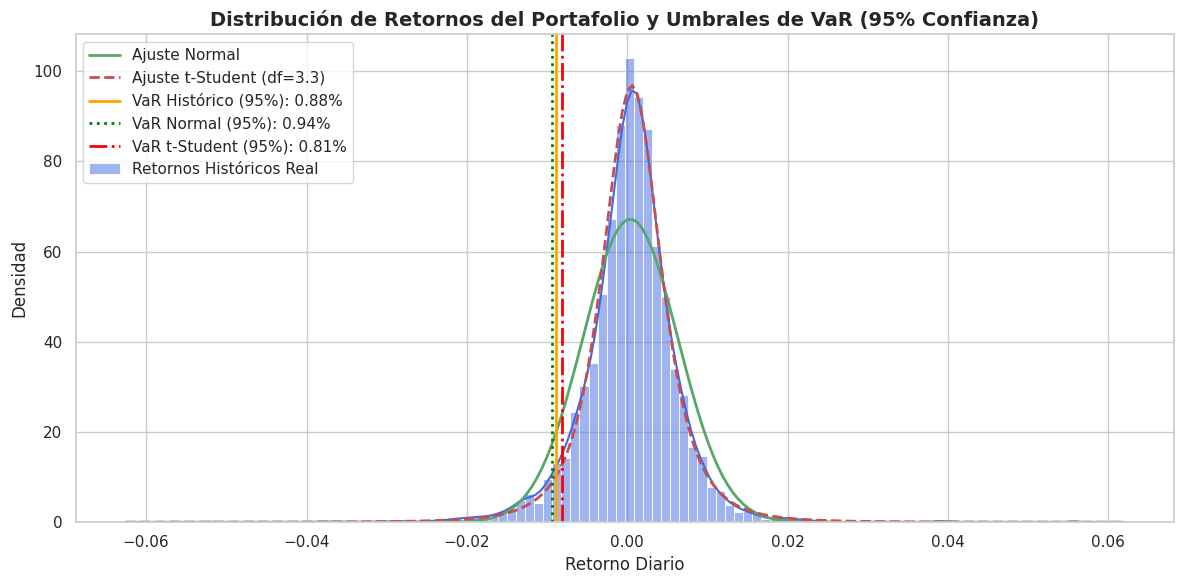

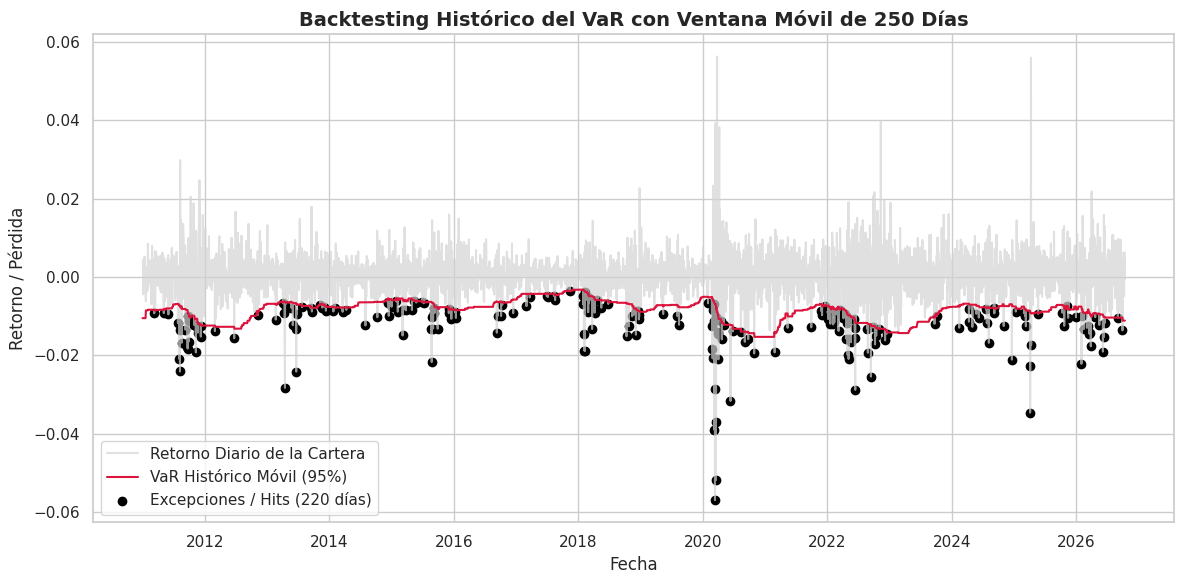

¡Gráficos generados con éxito y guardados en la carpeta 'outputs/'!


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from scipy.stats import norm, t

# Configuración estética de los gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Asegurar que exista la carpeta outputs
import os
os.makedirs("outputs", exist_ok=True)

# -------------------------------------------------------------
# GRÁFICO 1: Distribución de Retornos vs VaR (Normal vs t-Student)
# -------------------------------------------------------------
returns = data["portfolio_simple_return"].dropna()
portfolio_value = 100000
alpha = 0.05 # Nivel de confianza al 95%

# Parámetros ajustados
mu, sigma = returns.mean(), returns.std(ddof=1)
df_t, loc_t, scale_t = t.fit(returns)

var_hist = -returns.quantile(alpha)
var_norm = -(mu + norm.ppf(alpha) * sigma)
var_t = -(loc_t + t.ppf(alpha, df_t) * scale_t)

plt.figure()
sns.histplot(returns, bins=100, kde=True, color='royalblue', stat='density', label='Retornos Históricos Real')

# Eje X para las curvas teóricas
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 200)
plt.plot(x, norm.pdf(x, mu, sigma), 'g-', linewidth=2, label='Ajuste Normal')
plt.plot(x, t.pdf(x, df_t, loc_t, scale_t), 'r--', linewidth=2, label=f'Ajuste t-Student (df={df_t:.1f})')

# Líneas verticales de VaR al 95%
plt.axvline(-var_hist, color='orange', linestyle='-', linewidth=2, label=f'VaR Histórico (95%): {var_hist*100:.2f}%')
plt.axvline(-var_norm, color='green', linestyle=':', linewidth=2, label=f'VaR Normal (95%): {var_norm*100:.2f}%')
plt.axvline(-var_t, color='red', linestyle='-.', linewidth=2, label=f'VaR t-Student (95%): {var_t*100:.2f}%')

plt.title("Distribución de Retornos del Portafolio y Umbrales de VaR (95% Confianza)", fontsize=14, fontweight='bold')
plt.xlabel("Retorno Diario", fontsize=12)
plt.ylabel("Densidad", fontsize=12)
plt.legend(loc='upper left')
plt.tight_layout()
plt.savefig("outputs/var_distribution_comparison.png", dpi=300)
plt.show()

# -------------------------------------------------------------
# GRÁFICO 2: Backtesting Dinámico del VaR (Ventana Móvil de 250 días)
# -------------------------------------------------------------
window = 250
backtest_dates = returns.index[window:]
backtest_returns = returns.iloc[window:]

hist_var_rolling = [-returns.iloc[i-window:i].quantile(alpha) for i in range(window, len(returns))]
series_hist_var = pd.Series(hist_var_rolling, index=backtest_dates)

plt.figure()
plt.plot(backtest_returns.index, backtest_returns, color='lightgray', label='Retorno Diario de la Cartera', alpha=0.7)
plt.plot(series_hist_var.index, -series_hist_var, color='crimson', linewidth=1.5, label='VaR Histórico Móvil (95%)')

# Identificar excepciones
exceptions = backtest_returns < -series_hist_var
plt.scatter(backtest_returns[exceptions].index, backtest_returns[exceptions], color='black', marker='o', label=f'Excepciones / Hits ({exceptions.sum()} días)')

plt.title("Backtesting Histórico del VaR con Ventana Móvil de 250 Días", fontsize=14, fontweight='bold')
plt.xlabel("Fecha", fontsize=12)
plt.ylabel("Retorno / Pérdida", fontsize=12)
plt.legend(loc='lower left')
plt.tight_layout()
plt.savefig("outputs/backtesting_var_chart.png", dpi=300)
plt.show()

print("¡Gráficos generados con éxito y guardados en la carpeta 'outputs/'!")